# PitchTrack example — melody and tonal system of a vocal piece

This notebook walks one recording through the **full `PitchTrack` pipeline**,
one step at a time, with an explanation before each step:

1. **Pitch extraction** — the fundamental frequency (f0) over time.
2. **Note / melody detection** — segmenting f0 into discrete notes.
3. **Tonal system** — which scale the piece uses.
4. **Melodic n-grams** — the most frequent interval patterns.

**Example piece.** `CAM-5_SARA PANH.wav`, a Cambodian solo vocal recording.
A single clear voice makes every step easy to follow, and the microtonal
inflections make the tonal-system step interesting.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from comsar import PitchTrack, pitch_player

WAV = "CAM-5_SARA PANH.wav"


## 1. Pitch extraction (f0)

`PitchTrack` estimates the fundamental frequency with a self-contained,
octave-robust **YIN** detector. You set:

- `window_ms` / `overlap` — the time grid (here a point every ~10 ms);
- `f_min` / `f_max` — the frequency range to search (a human voice sits well
  inside 80–1000 Hz).

`extract` returns a result whose `.features` table is indexed by time in
seconds and holds the `Pitch` (Hz, 0 where unvoiced) and `SPL` columns.

In [3]:
pt = PitchTrack(window_ms=25, overlap=0.6, f_min=80, f_max=1000)
result = pt.extract(WAV)
print(f"{len(result.features)} frames, "
      f"{(result.features['Pitch'] > 0).mean():.0%} voiced")
result.features.head()

Pitch ... 0.0002751 s.
SPL ... 0.1148 s.
13992 frames, 84% voiced


,Pitch,SPL
time_s,,
0.00,0.0,47.984523
0.01,0.0,55.041047
0.02,0.0,56.375314
0.03,0.0,55.698298
0.04,0.0,54.021719


Plotting the f0 track (voiced frames only, on a log-frequency axis) shows the
sung melodic line and its ornaments. Gaps are unvoiced frames (breaths,
consonants, rests).

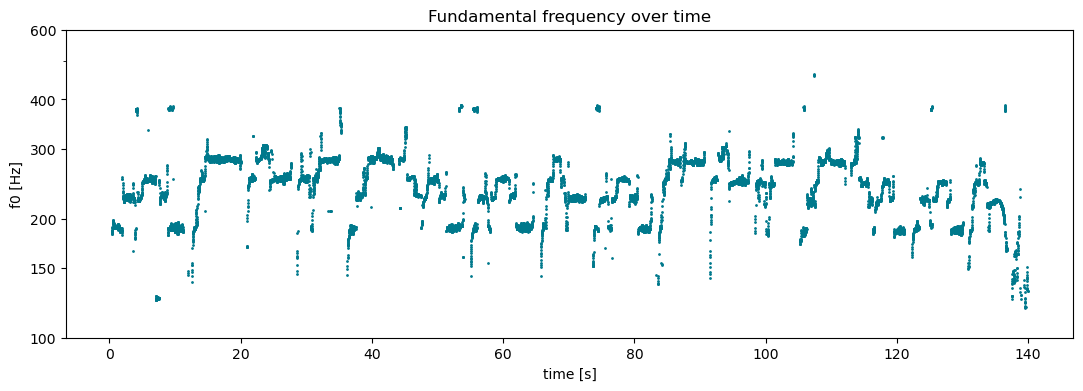

In [4]:
f0 = result.features["Pitch"]
voiced = f0 > 0

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(f0.index[voiced], f0[voiced], ".", ms=2, color="#00798c")
ax.set_yscale("log")
ax.set_yticks([100, 150, 200, 300, 400, 600])
ax.get_yaxis().set_major_formatter(plt.ScalarFormatter())
ax.set_xlabel("time [s]"); ax.set_ylabel("f0 [Hz]")
ax.set_title("Fundamental frequency over time")
plt.show()

## 2. Note / melody detection

`notes()` segments the continuous f0 track into discrete **notes**: a note is a
run of at least `minlen` frames whose pitch stays within `mindev` cent of its
mean. The result is one row per note with start/stop time, duration, and pitch
as frequency, cent (above a reference) and MIDI number.

In [5]:
notes = pt.notes(result)
print(f"{len(notes)} notes detected")
notes.head()

189 notes detected


,start_s,stop_s,duration_s,frequency,cent,midi
0,0.47,1.41,0.94,189.869,3345.0,54
1,1.43,1.96,0.53,185.854,3308.0,54
2,2.05,2.22,0.17,221.530,3612.0,57
3,2.24,3.44,1.20,225.924,3646.0,57
4,3.68,3.87,0.19,225.012,3639.0,57


Drawn as a **piano roll** (each note a horizontal bar at its MIDI pitch,
spanning its duration) this is the extracted melody.

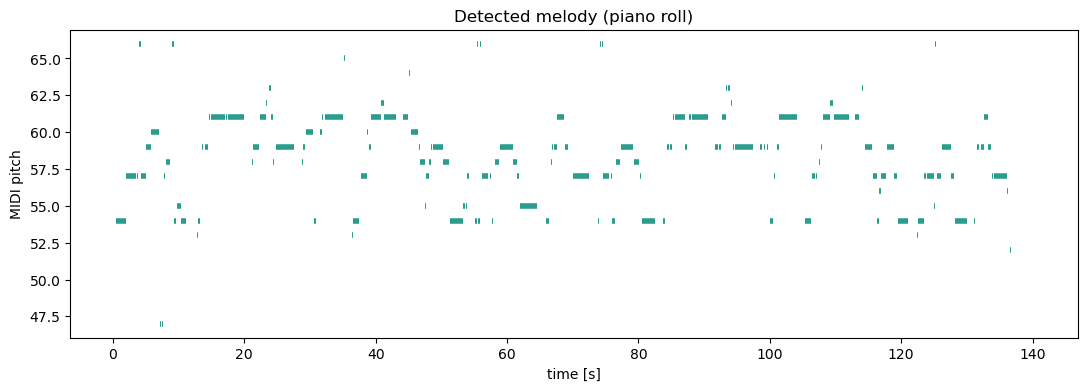

In [6]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.hlines(notes["midi"], notes["start_s"], notes["stop_s"],
          color="#2a9d8f", lw=4)
ax.set_xlabel("time [s]"); ax.set_ylabel("MIDI pitch")
ax.set_title("Detected melody (piano roll)")
plt.show()

## 3. Tonal system (scale)

`tonal_system()` accumulates all measured pitches into a **single octave** and
correlates that distribution with 900+ theoretical scales (`scales.csv`). It
returns the best-matching scales, the measured one-octave distribution, and the
strongest frequency of the recording.

In [7]:
ts = pt.tonal_system(result)
print(f"fundamental: {ts.fundamental:.1f} Hz")
print(f"best match : {ts.best['name']}  (correlation {ts.best['correlation']:.3f})")
ts.scales[["rank", "name", "correlation"]]

fundamental: 279.3 Hz
best match : Chromatic_7-Tone_Equal_Temperament_7TET  (correlation 0.346)


,rank,name,correlation
0,1,Chromatic_7-Tone_Equal_Temperament_7TET,0.345653
1,2,Thai_Mode_3_7TET,0.345653
2,3,Dastgah-e_Nava_Per17,0.337753
3,4,Dastgah-e_Sehgah_Per17,0.337753
4,5,Eight_Tone_Spanish_12TET,0.335778
5,6,Harmonic_Chromatic_Ascending_12TET,0.335778
6,7,Hijaz_Major_12TET,0.335778
7,8,LocrianAeolian_Mixed_12TET,0.335778
8,9,Locrian_12TET,0.335778
9,10,Maqam_Tarzanuyn_12TET,0.335778


The **measured one-octave pitch distribution** (how much time the voice
spends at each cent position within an octave) with the degrees of the
best-matching scale marked as dashed lines — where the peaks and the scale
steps line up is why this scale was chosen.

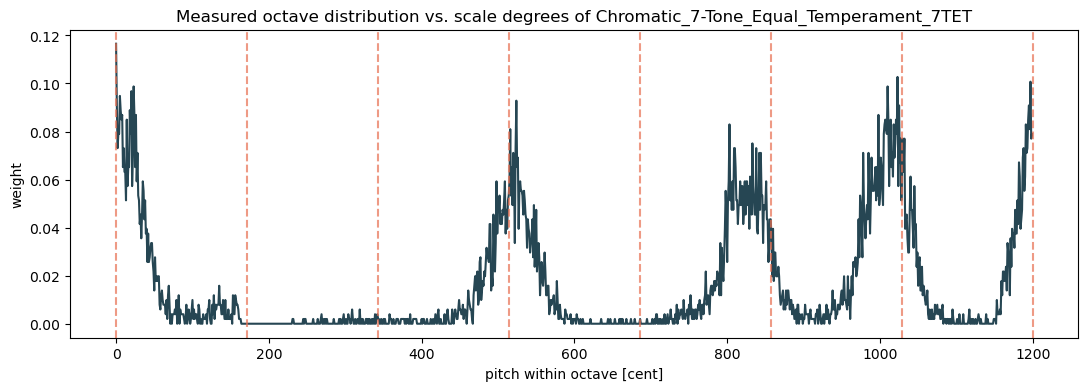

In [8]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(np.arange(len(ts.octave)), ts.octave, color="#264653")
for d in ts.best["degrees_cent"]:
    ax.axvline(d, color="#e76f51", ls="--", alpha=0.7)
ax.set_xlabel("pitch within octave [cent]"); ax.set_ylabel("weight")
ax.set_title(f"Measured octave distribution vs. scale degrees of "
             f"{ts.best['name']}")
plt.show()

## 4. Melodic n-grams

`ngrams()` turns the melody into a sequence of pitch **intervals** (in cent,
quantised to semitones) and returns the most frequent interval patterns.
Because it uses intervals, not absolute pitches, the fingerprint is
**transposition-invariant**. A 3-gram spans two successive intervals.

In [9]:
ng = pt.ngrams(result, ngram=3)
ng

,interval_1_cent,interval_2_cent
0,0,-100
1,0,0
2,-100,0
3,-100,-100
4,100,0
5,-200,0
6,-100,-300
7,-100,-200
8,0,-200
9,0,100


## 5. Interactive player

`pitch_player` combines everything in one interactive view: the waveform, the
f0 track, the detected notes and the tonal-system reference lines — with
play / zoom / seek. Run this cell to produce it (it embeds the audio, so its
output is not saved with the notebook).

In [ ]:
pitch_player(WAV, result, notes=notes, tonal_system=ts)